--- JUTE LAYER ---
RMSE: 0.2848 K | MAE: 0.2275 K
--- SYNTHETIC LAYER ---
RMSE: 0.3171 K | MAE: 0.2282 K


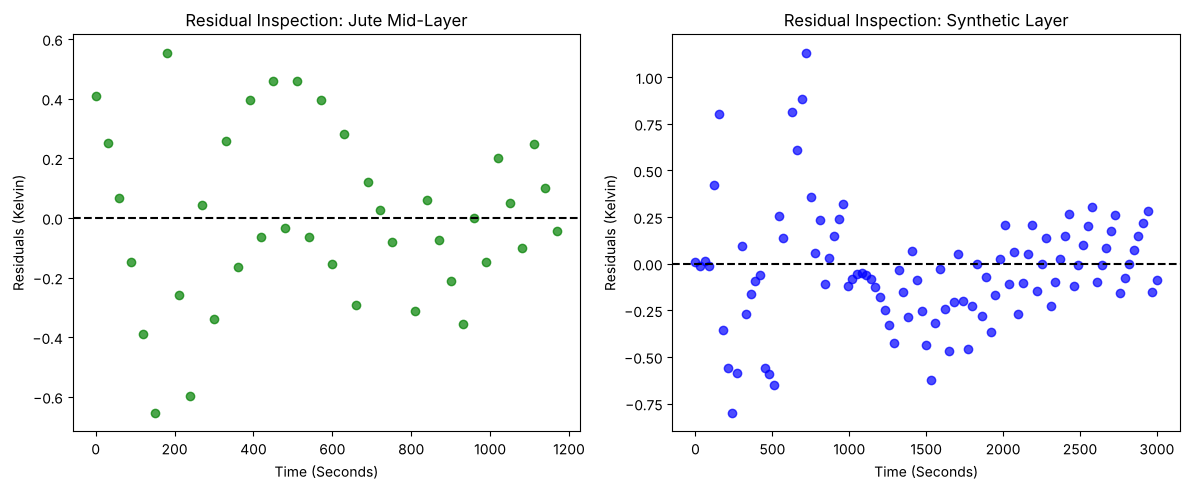

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Load your datasets (ensure these match your actual file names)
# df_jute = pd.read_csv('data.xlsx')
jute = pd.read_csv('Jute.csv')
synthetic = pd.read_csv('synthetic.csv')
# Standardize column names based on your CSV structure
time_jute = jute.iloc[:, 0].values
temp_jute_actual = jute.iloc[:, 1].values

time_syn = synthetic.iloc[:, 0].values
temp_syn_actual = synthetic.iloc[:, 1].values

# 2. Define your prediction models: Equation 5 (jute, cubic) and Equation 7 (polyester, double exponential),
#    with the coefficients exactly as printed in the manuscript.

def predict_jute(x):
    return -5.088e-9 * x**3 + 1.606e-5 * x**2 - 0.02853 * x + 349.59

def predict_synthetic(x):
    return 49.44 * np.exp(-0.00108 * x) + 0.40 * np.exp(-0.523 * x) + 302.15

# 3. Calculate predicted values and residuals
temp_jute_pred = predict_jute(time_jute)
residuals_jute = temp_jute_actual - temp_jute_pred

temp_syn_pred = predict_synthetic(time_syn)
residuals_syn = temp_syn_actual - temp_syn_pred

# 4. Calculate Goodness-of-Fit metrics (RMSE and MAE)
rmse_jute = np.sqrt(mean_squared_error(temp_jute_actual, temp_jute_pred))
mae_jute = mean_absolute_error(temp_jute_actual, temp_jute_pred)

rmse_syn = np.sqrt(mean_squared_error(temp_syn_actual, temp_syn_pred))
mae_syn = mean_absolute_error(temp_syn_actual, temp_syn_pred)

print(f"--- JUTE LAYER ---")
print(f"RMSE: {rmse_jute:.4f} K | MAE: {mae_jute:.4f} K")
print(f"--- SYNTHETIC LAYER ---")
print(f"RMSE: {rmse_syn:.4f} K | MAE: {mae_syn:.4f} K")

# 5. Plot Residuals for inspection
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Jute Residual Plot
ax1.scatter(time_jute, residuals_jute, color='green', alpha=0.7)
ax1.axhline(y=0, color='black', linestyle='--')
ax1.set_title('Residual Inspection: Jute Mid-Layer')
ax1.set_xlabel('Time (Seconds)')
ax1.set_ylabel('Residuals (Kelvin)')

# Synthetic Residual Plot
ax2.scatter(time_syn, residuals_syn, color='blue', alpha=0.7)
ax2.axhline(y=0, color='black', linestyle='--')
ax2.set_title('Residual Inspection: Synthetic Layer')
ax2.set_xlabel('Time (Seconds)')
ax2.set_ylabel('Residuals (Kelvin)')

plt.tight_layout()
plt.show()

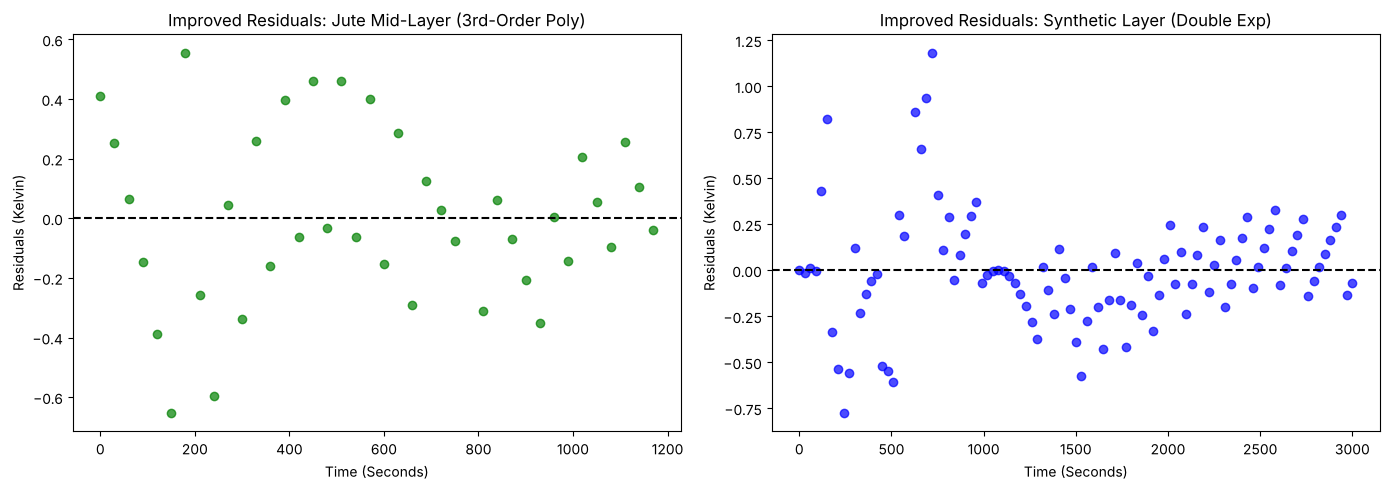

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load the datasets
df_jute = pd.read_csv('Jute.csv')
df_syn = pd.read_csv('synthetic.csv')

t_jute = df_jute.iloc[:, 0].values
T_jute = df_jute.iloc[:, 1].values

t_syn = df_syn.iloc[:, 0].values
T_syn = df_syn.iloc[:, 1].values


# 1. Jute: 3rd-Order Polynomial
# This fit gives Equation 5 of the manuscript: T(t) = a3*t^3 + a2*t^2 + a1*t + a0.
# popt_jute = [a3, a2, a1, a0] = [-5.088e-9, 1.606e-5, -0.02853, 349.59]
# (the manuscript prints these rounded to 4 significant figures)
popt_jute = np.polyfit(t_jute, T_jute, 3)
pred_jute = np.polyval(popt_jute, t_jute)

# 2. Synthetic: Double Exponential Decay
# This fit gives Equation 7 of the manuscript: T(t) = A*exp(-k1*t) + B*exp(-k2*t) + T_inf.
# In double_exp below, (a, b, c, d, e) = (A, k1, B, k2, T_inf).
# popt_syn = [49.44, 0.001084, 0.40, 0.523, 302.15] (Equation 7 prints k1 as 0.00108).
# k2 is not identifiable from readings taken every 30 s (see the footnote to Table 6),
# so its fitted value is arbitrary and is only kept so that the equation can be drawn.

def double_exp(x, a, b, c, d, e):
    return a * np.exp(-b * x) + c * np.exp(-d * x) + e

# Initial guess to help the algorithm find the right fit
p0_syn = [25, 0.001, 25, 0.01, 300]
popt_syn, _ = curve_fit(double_exp, t_syn, T_syn, p0=p0_syn, maxfev=10000)
pred_syn = double_exp(t_syn, *popt_syn)

# Calculate Residuals
res_jute = T_jute - pred_jute
res_syn = T_syn - pred_syn

# Plotting the Residuals
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Jute Residual Plot
ax1.scatter(t_jute, res_jute, color='green', alpha=0.7)
ax1.axhline(y=0, color='black', linestyle='--')
ax1.set_title('Improved Residuals: Jute Mid-Layer (3rd-Order Poly)')
ax1.set_xlabel('Time (Seconds)')
ax1.set_ylabel('Residuals (Kelvin)')

# Synthetic Residual Plot
ax2.scatter(t_syn, res_syn, color='blue', alpha=0.7)
ax2.axhline(y=0, color='black', linestyle='--')
ax2.set_title('Improved Residuals: Synthetic Layer (Double Exp)')
ax2.set_xlabel('Time (Seconds)')
ax2.set_ylabel('Residuals (Kelvin)')

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# Cell 1: final models (Equation 5 and Equation 7) and goodness of fit
# ============================================================
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

# curve_fit warns that the covariance cannot be estimated for the double exponential. That is expected:
# k2 cannot be determined from readings taken every 30 s (see cell 4), so the warning is silenced here.
warnings.filterwarnings('ignore', category=optimize.OptimizeWarning)

rng = np.random.default_rng(0)          # one generator, used in cells 3 and 4 (run top to bottom to reproduce the numbers)

# --- data (same files and column convention as the cells above) ---
df_jute = pd.read_csv('Jute.csv')
df_syn = pd.read_csv('synthetic.csv')
t_jute, T_jute = df_jute.iloc[:, 0].values.astype(float), df_jute.iloc[:, 1].values.astype(float)
t_syn, T_syn = df_syn.iloc[:, 0].values.astype(float), df_syn.iloc[:, 1].values.astype(float)

# --- Equation 5, woven jute: cubic polynomial (least squares), rounded as printed in the manuscript ---
c_fit = np.polyfit(t_jute, T_jute, 3)                                        # a3, a2, a1, a0
c_eq5 = np.array([float(f'{v:.4g}') for v in c_fit[:3]] + [round(c_fit[3], 2)])

def eq5(x, c=c_eq5):
    return np.polyval(c, x)

# --- Equation 7, recycled polyester: double exponential ---
def double_exp(x, a, b, c, d, e):                                            # A, k1, B, k2, T_inf
    return a * np.exp(-b * x) + c * np.exp(-d * x) + e

EQ7_PRINTED = (49.44, 0.00108, 0.40, 0.523, 302.15)                          # coefficients printed in the manuscript
popt_syn, _ = optimize.curve_fit(double_exp, t_syn, T_syn, p0=[25, 0.001, 25, 0.01, 300], maxfev=10000)

print('Equation 5 (jute):  T(t) = {:.4g} t^3 + {:.4g} t^2 + {:.4g} t + {:.2f}'.format(*c_eq5))
print('Equation 7 refitted: A = {:.4f}, k1 = {:.6g}, B = {:.4f}, k2 = {:.4g}, T_inf = {:.3f}'.format(*popt_syn))
print('Equation 7 printed:  A = {}, k1 = {}, B = {}, k2 = {}, T_inf = {}\n'.format(*EQ7_PRINTED))

def fit_metrics(y, pred):
    r = y - pred
    return {'RMSE (K)': np.sqrt(mean_squared_error(y, pred)),
            'MAE (K)': mean_absolute_error(y, pred),
            'R2': r2_score(y, pred),
            'mean residual (K)': r.mean(),
            'Durbin-Watson': np.sum(np.diff(r) ** 2) / np.sum(r ** 2)}

table = pd.DataFrame({
    'Jute: Equation 5 as printed (cubic)':      fit_metrics(T_jute, eq5(t_jute)),
    'Jute: cubic, unrounded coefficients':      fit_metrics(T_jute, np.polyval(c_fit, t_jute)),
    'Synthetic: Equation 7 as printed':         fit_metrics(T_syn, double_exp(t_syn, *EQ7_PRINTED)),
    'Synthetic: Equation 7 refitted':           fit_metrics(T_syn, double_exp(t_syn, *popt_syn)),
}).T
display(table.round(4))


Equation 5 (jute):  T(t) = -5.088e-09 t^3 + 1.606e-05 t^2 + -0.02853 t + 349.59
Equation 7 refitted: A = 49.4425, k1 = 0.00108351, B = 0.4026, k2 = 0.523, T_inf = 302.155
Equation 7 printed:  A = 49.44, k1 = 0.00108, B = 0.4, k2 = 0.523, T_inf = 302.15



,RMSE (K),MAE (K),R2,mean residual (K),Durbin-Watson
Jute: Equation 5 as printed (cubic),0.2848,0.2275,0.9975,-0.0028,2.2388
"Jute: cubic, unrounded coefficients",0.2848,0.2275,0.9975,-0.0000,2.2390
Synthetic: Equation 7 as printed,0.3171,0.2282,0.9994,-0.0352,0.8086
Synthetic: Equation 7 refitted,0.3148,0.2213,0.9994,0.0000,0.8206


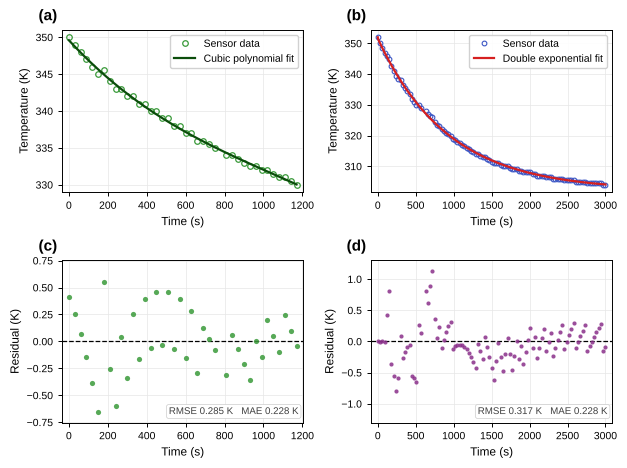

In [4]:
# ============================================================
# Cell 2: Figure 4 (cooling curves and residuals), saved as PNG (600 dpi), PDF and SVG
# ============================================================
FIG_DPI = 600
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 8, 'axes.labelsize': 8.5, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'legend.fontsize': 7.5, 'axes.linewidth': 0.7, 'svg.fonttype': 'none', 'pdf.fonttype': 42,
})
GREEN, DGREEN, BLUE, RED, PURPLE = '#3a9a3a', '#0b4d0b', '#3b55c4', '#d62020', '#8a2f8a'

def eq7_printed(x):
    return double_exp(x, *EQ7_PRINTED)

def style(ax, ylabel, tmax):
    ax.set_xlabel('Time (s)')
    ax.set_ylabel(ylabel)
    ax.set_xlim(-0.03 * tmax, 1.03 * tmax)
    ax.grid(True, color='0.9', lw=0.5)
    ax.set_axisbelow(True)
    ax.tick_params(width=0.7, length=3)

fig, axs = plt.subplots(2, 2, figsize=(7.1, 5.1), gridspec_kw=dict(hspace=0.42, wspace=0.28))

# (a) jute: drawn only over the measured window (the cubic does not extrapolate)
tg = np.linspace(t_jute.min(), t_jute.max(), 400)
axs[0, 0].plot(t_jute, T_jute, 'o', mfc='none', mec=GREEN, mew=0.9, ms=4, label='Sensor data')
axs[0, 0].plot(tg, eq5(tg), '-', color=DGREEN, lw=1.6, label='Cubic polynomial fit')
style(axs[0, 0], 'Temperature (K)', t_jute.max())
axs[0, 0].legend(frameon=True, framealpha=0.9, edgecolor='0.8')

# (b) polyester: Equation 7 as printed
tg = np.linspace(t_syn.min(), t_syn.max(), 600)
axs[0, 1].plot(t_syn, T_syn, 'o', mfc='none', mec=BLUE, mew=0.8, ms=3.4, label='Sensor data')
axs[0, 1].plot(tg, eq7_printed(tg), '-', color=RED, lw=1.6, label='Double exponential fit')
style(axs[0, 1], 'Temperature (K)', t_syn.max())
axs[0, 1].legend(frameon=True, framealpha=0.9, edgecolor='0.8')

# (c), (d) residuals = observed - fitted
for ax, t, y, model, col, size in ((axs[1, 0], t_jute, T_jute, eq5, GREEN, 14),
                                   (axs[1, 1], t_syn, T_syn, eq7_printed, PURPLE, 9)):
    res = y - model(t)
    ax.axhline(0, color='k', ls='--', lw=0.9)
    ax.scatter(t, res, s=size, color=col, alpha=0.85, lw=0, zorder=3)
    lim = 1.15 * np.abs(res).max()
    ax.set_ylim(-lim, lim)
    style(ax, 'Residual (K)', t.max())
    rmse, mae = np.sqrt(mean_squared_error(y, model(t))), mean_absolute_error(y, model(t))
    ax.text(0.98, 0.04, f'RMSE {rmse:.3f} K   MAE {mae:.3f} K', transform=ax.transAxes, ha='right', va='bottom',
            fontsize=7, color='0.25', bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='0.8', lw=0.5))

for ax, lab in zip(axs.flat, 'abcd'):
    ax.text(-0.02, 1.04, f'({lab})', transform=ax.transAxes, ha='right', va='bottom', fontsize=11, fontweight='bold')

for ext in ('png', 'pdf', 'svg'):
    fig.savefig(f'Figure4.{ext}', dpi=FIG_DPI, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()

In [5]:
# ============================================================
# Cell 3: jute layer. 95% confidence intervals (Table 6) and overfitting checks
# ============================================================
def poly_ols(t, y, deg, s=1000.0):
    """Least-squares polynomial with its covariance matrix (time is divided by s only for numerical conditioning)."""
    X = np.vander(t / s, deg + 1, increasing=True)
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b
    n, p = X.shape
    cov = (e @ e / (n - p)) * np.linalg.inv(X.T @ X)
    scale = np.array([s ** -k for k in range(p)])                       # back to units of seconds
    h = np.einsum('ij,ji->i', X, np.linalg.solve(X.T @ X, X.T))         # leverages, for leave-one-out CV
    return dict(b=b * scale, cov=cov * np.outer(scale, scale), e=e, h=h, p=p, dof=n - p, ssr=e @ e)

n = len(t_jute)
fits = {d: poly_ols(t_jute, T_jute, d) for d in range(1, 6)}
f3 = fits[3]

# ---- 95% confidence intervals of the cubic coefficients (Student's t, n - 4 degrees of freedom)
tc = stats.t.ppf(0.975, f3['dof'])
se = np.sqrt(np.diag(f3['cov']))
rows = []
for i, name in [(3, 'a3 (K s^-3)'), (2, 'a2 (K s^-2)'), (1, 'a1 (K s^-1)'), (0, 'a0 (K)')]:
    b = f3['b'][i]
    rows.append([name, b, se[i], b - tc * se[i], b + tc * se[i], 2 * stats.t.sf(abs(b / se[i]), f3['dof'])])
ci_jute = pd.DataFrame(rows, columns=['parameter', 'estimate', 'std. error', 'CI low', 'CI high', 'p-value']).set_index('parameter')
print(f'Jute cubic, n = {n}, {f3["dof"]} degrees of freedom, t(0.975) = {tc:.3f}')
display(ci_jute.map(lambda v: f'{v:.5g}'))

e3 = f3['e']
print(f'Residuals: Durbin-Watson {np.sum(np.diff(e3) ** 2) / np.sum(e3 ** 2):.2f}, '
      f'lag-1 r {np.corrcoef(e3[:-1], e3[1:])[0, 1]:.2f}, Shapiro-Wilk p {stats.shapiro(e3).pvalue:.2f}\n')

# ---- overfitting check 1: polynomial order (in-sample RMSE, leave-one-out RMSE, AICc, BIC)
order_rows = []
for d in range(2, 6):
    f, p = fits[d], fits[d]['p']
    order_rows.append([d, np.sqrt(f['ssr'] / n),
                       np.sqrt(np.mean((f['e'] / (1 - f['h'])) ** 2)),                       # exact LOOCV via leverages
                       n * np.log(f['ssr'] / n) + 2 * p + 2 * p * (p + 1) / (n - p - 1),     # AICc
                       n * np.log(f['ssr'] / n) + p * np.log(n)])                            # BIC
display(pd.DataFrame(order_rows, columns=['order', 'RMSE (K)', 'LOOCV RMSE (K)', 'AICc', 'BIC']).set_index('order').round(4))

for a, b in [(2, 3), (3, 4), (4, 5)]:                                                        # partial F-tests
    F = (fits[a]['ssr'] - fits[b]['ssr']) / (fits[b]['ssr'] / fits[b]['dof'])
    print(f'partial F-test, order {a} -> {b}: F(1, {fits[b]["dof"]}) = {F:.2f}, p = {stats.f.sf(F, 1, fits[b]["dof"]):.4f}')

# ---- overfitting check 2: repeated k-fold cross-validation of the cubic
def repeated_kfold(deg, k, reps=500):
    out = []
    for _ in range(reps):
        idx = rng.permutation(n)
        sse = 0.0
        for fold in np.array_split(idx, k):
            train = np.setdiff1d(idx, fold)
            b = np.linalg.lstsq(np.vander(t_jute[train] / 1000, deg + 1, increasing=True), T_jute[train], rcond=None)[0]
            sse += np.sum((T_jute[fold] - np.vander(t_jute[fold] / 1000, deg + 1, increasing=True) @ b) ** 2)
        out.append(np.sqrt(sse / n))
    return np.mean(out)

print(f'\ncubic, repeated 5-fold CV RMSE (500 repeats): {repeated_kfold(3, 5):.4f} K;  10-fold: {repeated_kfold(3, 10):.4f} K')

# ---- overfitting check 3: forward validation (fit the first 80% of the record, predict the last 20%)
ntr = int(round(0.8 * n))
for d in (2, 3, 4):
    b = np.linalg.lstsq(np.vander(t_jute[:ntr] / 1000, d + 1, increasing=True), T_jute[:ntr], rcond=None)[0]
    pred = np.vander(t_jute[ntr:] / 1000, d + 1, increasing=True) @ b
    print(f'forward validation, order {d}: fitted to t <= {t_jute[ntr - 1]:.0f} s, '
          f'RMSE on the last {n - ntr} readings = {np.sqrt(np.mean((T_jute[ntr:] - pred) ** 2)):.3f} K')


Jute cubic, n = 39, 35 degrees of freedom, t(0.975) = 2.030


,estimate,std. error,CI low,CI high,p-value
parameter,,,,,
a3 (K s^-3),-5.088e-09,1.4843e-09,-8.1014e-09,-2.0747e-09,0.0015728
a2 (K s^-2),1.6057e-05,2.6335e-06,1.071e-05,2.1403e-05,5.7547e-07
a1 (K s^-1),-0.02853,0.001308,-0.031185,-0.025875,5.874e-22
a0 (K),349.59,0.17376,349.24,349.94,3.3246e-90


Residuals: Durbin-Watson 2.24, lag-1 r -0.15, Shapiro-Wilk p 0.76



,RMSE (K),LOOCV RMSE (K),AICc,BIC
order,,,,
2,0.3292,0.3663,-79.9889,-75.6839
3,0.2848,0.3177,-88.7876,-83.3098
4,0.2599,0.3014,-93.2978,-86.7982
5,0.2385,0.2759,-97.1665,-89.8101


partial F-test, order 2 -> 3: F(1, 35) = 11.75, p = 0.0016
partial F-test, order 3 -> 4: F(1, 34) = 6.84, p = 0.0132
partial F-test, order 4 -> 5: F(1, 33) = 6.16, p = 0.0183



cubic, repeated 5-fold CV RMSE (500 repeats): 0.3236 K;  10-fold: 0.3197 K
forward validation, order 2: fitted to t <= 930 s, RMSE on the last 8 readings = 0.462 K
forward validation, order 3: fitted to t <= 930 s, RMSE on the last 8 readings = 1.413 K
forward validation, order 4: fitted to t <= 930 s, RMSE on the last 8 readings = 1.033 K


In [6]:
# ============================================================
# Cell 4: polyester layer. Confidence intervals, identifiability of k2, bootstrap, model comparison
# ============================================================
n = len(t_syn)
A, k1, B, k2, C = popt_syn
e = T_syn - double_exp(t_syn, *popt_syn)
dof = n - 5                                    # all five parameters of Equation 7 are counted, as in the manuscript
s2 = e @ e / dof

# Jacobian of the model with respect to (A, k1, B, k2, T_inf)
J = np.c_[np.exp(-k1 * t_syn), -A * t_syn * np.exp(-k1 * t_syn),
          np.exp(-k2 * t_syn), -B * t_syn * np.exp(-k2 * t_syn), np.ones_like(t_syn)]
col_norm = np.linalg.norm(J, axis=0)
k2_identifiable = (col_norm[3] / col_norm[1] > 1e-6) and (np.linalg.cond(J / col_norm) < 1e6)
print(f'Is k2 estimable from readings every {np.median(np.diff(t_syn)):.0f} s?  {k2_identifiable}  '
      f'(Jacobian column of k2 is {col_norm[3] / col_norm[1]:.1e} times that of k1)\n')

keep = [0, 1, 2, 4] if not k2_identifiable else [0, 1, 2, 3, 4]       # k2 left out of the covariance if it is not identifiable
names = np.array(['A (K)', 'k1 (1/s)', 'B (K)', 'k2 (1/s)', 'T_inf (K)'])
cov = s2 * np.linalg.inv(J[:, keep].T @ J[:, keep])
se = np.sqrt(np.diag(cov))
tc = stats.t.ppf(0.975, dof)
est = popt_syn[keep]
ci_syn = pd.DataFrame({'estimate': est, 'std. error': se, 'CI low': est - tc * se, 'CI high': est + tc * se},
                      index=names[keep])
print(f'Polyester, n = {n}, {dof} degrees of freedom, t(0.975) = {tc:.3f}')
shown = ci_syn.copy()
shown.loc['k1 (1/s)'] *= 1e3                               # shown in units of 1e-3 1/s for readability
shown = shown.rename(index={'k1 (1/s)': 'k1 (1e-3 1/s)'})
display(shown.map(lambda v: f'{v:.5g}'))
print(f'time constant 1/k1 = {1 / k1:.0f} s  (95% CI {1 / (k1 + tc * se[1]):.0f} to {1 / (k1 - tc * se[1]):.0f} s)')
print(f'Residuals: Durbin-Watson {np.sum(np.diff(e) ** 2) / (e @ e):.2f}, lag-1 r {np.corrcoef(e[:-1], e[1:])[0, 1]:.2f}\n')

# ---- profile of k2: how much worse does the fit get if k2 is fixed at other values?
g_fixed = lambda k: (lambda x, a, b, c, d: double_exp(x, a, b, c, k, d))
limit = s2 * stats.f.ppf(0.95, 1, dof)
print(f'k2 profile (a value is inside the 95% region if the increase in SSE is below {limit:.3f}):')
for k in (0.005, 0.01, 0.05, 0.1, 0.5, 1, 5):
    q, _ = optimize.curve_fit(g_fixed(k), t_syn, T_syn, p0=[A, k1, B, C], maxfev=50000)
    print(f'  k2 = {k:<6}: increase in SSE = {np.sum((T_syn - g_fixed(k)(t_syn, *q)) ** 2) - e @ e:+.4f}')

# ---- moving-block bootstrap of the residuals (the residuals are autocorrelated), k2 held at its fitted value
g = g_fixed(k2)
q0 = [A, k1, B, C]
fitted = g(t_syn, *q0)
L = 10
n_blocks = int(np.ceil(n / L))
boot = []
for _ in range(1500):
    starts = rng.integers(0, n - L + 1, n_blocks)
    resampled = np.concatenate([e[s:s + L] for s in starts])[:n]
    try:
        boot.append(optimize.curve_fit(g, t_syn, fitted + resampled, p0=q0, maxfev=5000)[0])
    except RuntimeError:
        pass
boot = np.array(boot)
print(f'\nblock-bootstrap 95% intervals (block length {L}, {len(boot)} resamples):')
for j, nm in enumerate(['A (K)', 'k1 (1/s)', 'B (K)', 'T_inf (K)']):
    lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
    print(f'  {nm:<10} {lo:.6g} to {hi:.6g}')

# ---- single versus double exponential
single = lambda x, a, b, c: a * np.exp(-b * x) + c
q1, _ = optimize.curve_fit(single, t_syn, T_syn, p0=[A, k1, C], maxfev=50000)
e1 = T_syn - single(t_syn, *q1)
print('\nmodel comparison:')
for label, sse, k in (('single exponential (3 parameters)', e1 @ e1, 3), ('double exponential (5 parameters)', e @ e, 5)):
    print(f'  {label}: RMSE {np.sqrt(sse / n):.4f} K, AICc {n * np.log(sse / n) + 2 * k + 2 * k * (k + 1) / (n - k - 1):.2f}, '
          f'BIC {n * np.log(sse / n) + k * np.log(n):.2f}')
print(f'  single exponential: A = {q1[0]:.3f} K, k = {q1[1]:.6g} 1/s, T_inf = {q1[2]:.3f} K')


Is k2 estimable from readings every 30 s?  False  (Jacobian column of k2 is 1.5e-11 times that of k1)

Polyester, n = 100, 95 degrees of freedom, t(0.975) = 1.985


,estimate,std. error,CI low,CI high
A (K),49.442,0.12834,49.188,49.697
k1 (1e-3 1/s),1.0835,0.0083078,1.067,1.1
B (K),0.40265,0.35209,-0.29634,1.1016
T_inf (K),302.15,0.10767,301.94,302.37


time constant 1/k1 = 923 s  (95% CI 909 to 937 s)
Residuals: Durbin-Watson 0.82, lag-1 r 0.59

k2 profile (a value is inside the 95% region if the increase in SSE is below 0.411):
  k2 = 0.005 : increase in SSE = +0.1365
  k2 = 0.01  : increase in SSE = +0.0305
  k2 = 0.05  : increase in SSE = +0.0079
  k2 = 0.1   : increase in SSE = +0.0010
  k2 = 0.5   : increase in SSE = +0.0000
  k2 = 1     : increase in SSE = -0.0000
  k2 = 5     : increase in SSE = -0.0000



block-bootstrap 95% intervals (block length 10, 1500 resamples):
  A (K)      49.0258 to 49.9267
  k1 (1/s)   0.00105548 to 0.00111201
  B (K)      -0.238392 to 0.998827
  T_inf (K)  301.802 to 302.536

model comparison:
  single exponential (3 parameters): RMSE 0.3170 K, AICc -223.51, BIC -215.95
  double exponential (5 parameters): RMSE 0.3148 K, AICc -220.49, BIC -208.11
  single exponential: A = 49.482 K, k = 0.00108622 1/s, T_inf = 302.178 K


In [7]:
# ============================================================
# Cell 5: residual diagnostics. Is the spread constant? Are the residuals independent? Robust intervals for the jute cubic
# ============================================================
def ljung_box(e, lags=10):
    """Ljung-Box test: are the first `lags` residual autocorrelations jointly zero?"""
    m = len(e)
    r = np.array([np.corrcoef(e[:-k], e[k:])[0, 1] for k in range(1, lags + 1)])
    q = m * (m + 2) * np.sum(r ** 2 / (m - np.arange(1, lags + 1)))
    return q, stats.chi2.sf(q, lags)

e_jute = T_jute - np.polyval(c_fit, t_jute)
e_syn = T_syn - double_exp(t_syn, *popt_syn)

rows = []
for label, e_, parts in (('jute (halves of the record)', e_jute, 2), ('polyester (thirds of the record)', e_syn, 3)):
    chunks = np.array_split(e_, parts)                                       # consecutive blocks of readings
    sds = ', '.join(f'{c.std(ddof=1):.3f}' for c in chunks)
    q, p_lb = ljung_box(e_)
    rows.append([label, sds, stats.levene(*chunks, center='median').pvalue, q, p_lb])
display(pd.DataFrame(rows, columns=['residuals', 'SD in each block (K)', 'Levene p (equal spread)',
                                    'Ljung-Box Q (10 lags)', 'Ljung-Box p']).set_index('residuals').map(lambda v: v if isinstance(v, str) else f'{v:.3g}'))

# ---- jute cubic: heteroscedasticity-robust (HC3) standard errors and intervals
n = len(t_jute)
X = np.vander(t_jute / 1000, 4, increasing=True)                              # same scaling as poly_ols in cell 3
XtX_inv = np.linalg.inv(X.T @ X)
lev = np.einsum('ij,jk,ik->i', X, XtX_inv, X)
meat = X.T @ (X * (f3['e'] ** 2 / (1 - lev) ** 2)[:, None])
scale = np.array([1000.0 ** -k for k in range(4)])
se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv)) * scale
se_ols = np.sqrt(np.diag(f3['cov']))
tcrit = stats.t.ppf(0.975, n - 4)
rows = []
for i, name in [(3, 'a3 (K s^-3)'), (2, 'a2 (K s^-2)'), (1, 'a1 (K s^-1)'), (0, 'a0 (K)')]:
    b = f3['b'][i]
    rows.append([name, se_ols[i], se_hc3[i], se_hc3[i] / se_ols[i], b - tcrit * se_hc3[i], b + tcrit * se_hc3[i]])
display(pd.DataFrame(rows, columns=['parameter', 'SE (least squares)', 'SE (HC3)', 'HC3 / LS', 'CI low (HC3)', 'CI high (HC3)']
                     ).set_index('parameter').map(lambda v: f'{v:.5g}'))


,SD in each block (K),Levene p (equal spread),Ljung-Box Q (10 lags),Ljung-Box p
residuals,,,,
jute (halves of the record),"0.363, 0.185",0.00463,24.8,0.00583
polyester (thirds of the record),"0.463, 0.182, 0.156",1.65e-05,57.3,1.17e-08


,SE (least squares),SE (HC3),HC3 / LS,CI low (HC3),CI high (HC3)
parameter,,,,,
a3 (K s^-3),1.4843e-09,1.6307e-09,1.0986,-8.3986e-09,-1.7775e-09
a2 (K s^-2),2.6335e-06,3.1137e-06,1.1823,9.7356e-06,2.2378e-05
a1 (K s^-1),0.001308,0.0016897,1.2918,-0.03196,-0.0251
a0 (K),0.17376,0.25144,1.4471,349.08,350.1
